# Fase 3: Modelado Predictivo y Evaluación de Resultados

**Proyecto:** Clasificación de Resoluciones de Reclamos en el Servicio de Gas Natural (ENARGAS 2026)  
**Objetivo:** Entrenar y comparar algoritmos de clasificación supervisada mediante `scikit-learn` sobre la partición temporal definida (Meses 1–6 para entrenamiento; Meses 7–8 para evaluación) para estimar la probabilidad de que un reclamo resulte *Procedente* (`1`) o *Improcedente* (`0`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# Configuración visual
sns.set_theme(style="whitegrid")

# 1. Carga de datos preprocesados en la Fase 2
train_df = pd.read_csv('../data/processed/train_reclamos_2026.csv')
test_df = pd.read_csv('../data/processed/test_reclamos_2026.csv')

# Separar predictores (X), objetivo (y) e identificador de trazabilidad
cols_excluir = ['id_registro_agregado', 'target_procedente']

X_train = train_df.drop(columns=cols_excluir)
y_train = train_df['target_procedente']

X_test = test_df.drop(columns=cols_excluir)
y_test = test_df['target_procedente']

print(f"Entrenamiento (Meses 1-6): {X_train.shape[0]:,} reclamos | {X_train.shape[1]} variables codificadas")
print(f"Evaluación    (Meses 7-8): {X_test.shape[0]:,} reclamos | {X_test.shape[1]} variables codificadas")
print(f"\nProporción clase Procedente (1) -> Train: {y_train.mean()*100:.2f}% | Test: {y_test.mean()*100:.2f}%")

Entrenamiento (Meses 1-6): 151,176 reclamos | 48 variables codificadas
Evaluación    (Meses 7-8): 58,315 reclamos | 48 variables codificadas

Proporción clase Procedente (1) -> Train: 29.75% | Test: 27.22%


In [2]:
# Definición de los modelos candidatos con control de desbalance (class_weight='balanced')
# y ajuste de hiperparámetros para evitar sobreajuste (overfitting) en datos expandidos
modelos = {
    "1. Regresión Logística (Base)": LogisticRegression(
        max_iter=1000, class_weight='balanced', C=1.0, random_state=42
    ),
    "2. Árbol de Decisión (Max Depth=8)": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=50, class_weight='balanced', random_state=42
    ),
    "3. Random Forest (Optimizado)": RandomForestClassifier(
        n_estimators=100, max_depth=10, min_samples_leaf=50, 
        class_weight='balanced', n_jobs=-1, random_state=42
    )
}

resultados = []
predicciones_test = {}
probabilidades_test = {}

for nombre, modelo in modelos.items():
    # Entrenamiento exclusivamente sobre Meses 1-6
    modelo.fit(X_train, y_train)
    
    # Predicciones sobre Meses 7-8 (futuro)
    y_pred = modelo.predict(X_test)
    y_proba = modelo.predict_proba(X_test)[:, 1]
    
    predicciones_test[nombre] = y_pred
    probabilidades_test[nombre] = y_proba
    
    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (Procedente)': precision_score(y_test, y_pred),
        'Recall (Procedente)': recall_score(y_test, y_pred),
        'F1-Score (Procedente)': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

df_resultados = pd.DataFrame(resultados)
print("=== COMPARATIVA DE MÉTRICAS EN CONJUNTO DE PRUEBA TEMPORAL (MESES 7-8) ===")
print(df_resultados.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

=== COMPARATIVA DE MÉTRICAS EN CONJUNTO DE PRUEBA TEMPORAL (MESES 7-8) ===
                            Modelo  Accuracy  Precision (Procedente)  Recall (Procedente)  F1-Score (Procedente)  ROC-AUC
     1. Regresión Logística (Base)    0.7454                  0.5362               0.4801                 0.5066   0.7114
2. Árbol de Decisión (Max Depth=8)    0.7402                  0.5214               0.5550                 0.5377   0.7402
     3. Random Forest (Optimizado)    0.7474                  0.5373               0.5190                 0.5280   0.7445


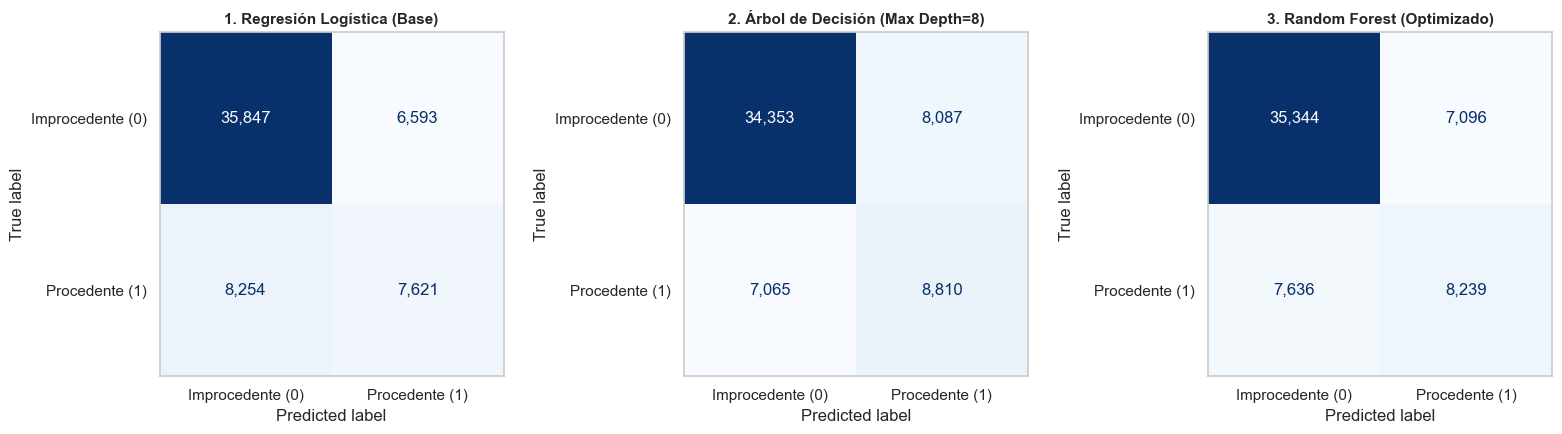

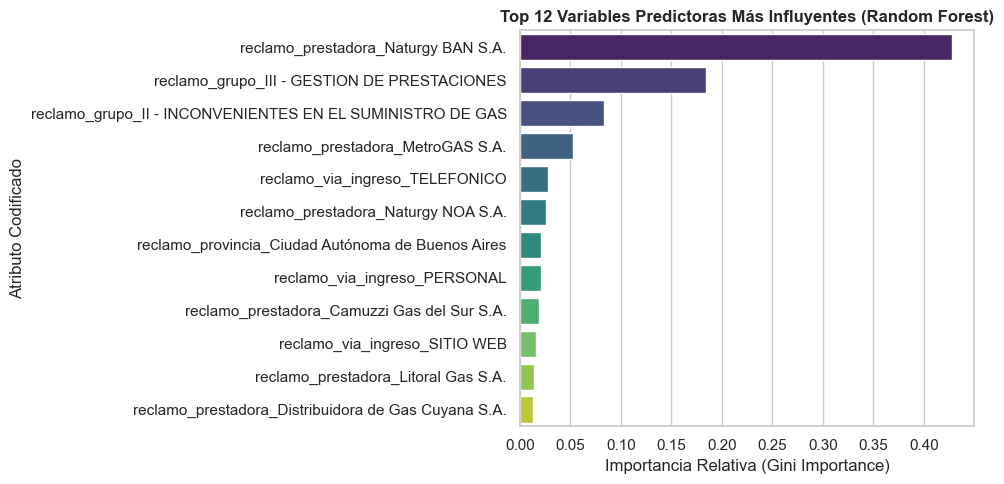

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for idx, (nombre, y_pred) in enumerate(predicciones_test.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Improcedente (0)', 'Procedente (1)'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False, values_format=',')
    axes[idx].set_title(nombre, fontsize=11, fontweight='bold')
    axes[idx].grid(False)

plt.tight_layout()
plt.show()

# Importancia de las 12 variables principales según Random Forest
rf_model = modelos["3. Random Forest (Optimizado)"]
importancias = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(12)

plt.figure(figsize=(10, 5))
sns.barplot(x=importancias.values, y=importancias.index, hue=importancias.index, palette='viridis', legend=False)
plt.title('Top 12 Variables Predictoras Más Influyentes (Random Forest)', fontweight='bold')
plt.xlabel('Importancia Relativa (Gini Importance)')
plt.ylabel('Atributo Codificado')
plt.tight_layout()
plt.show()

In [4]:
mejor_modelo_nombre = df_resultados.sort_values(by='F1-Score (Procedente)', ascending=False).iloc[0]['Modelo']
print(f"Reporte detallado para el modelo seleccionado: {mejor_modelo_nombre}\n")
print(classification_report(y_test, predicciones_test[mejor_modelo_nombre], target_names=['Improcedente (0)', 'Procedente (1)']))

Reporte detallado para el modelo seleccionado: 2. Árbol de Decisión (Max Depth=8)

                  precision    recall  f1-score   support

Improcedente (0)       0.83      0.81      0.82     42440
  Procedente (1)       0.52      0.55      0.54     15875

        accuracy                           0.74     58315
       macro avg       0.68      0.68      0.68     58315
    weighted avg       0.75      0.74      0.74     58315



## Conclusiones del Modelado Predictivo y Evaluación Temporal

1. **Desempeño Comparativo sobre el Futuro (Meses 7 y 8):**
   * Al evaluar los algoritmos sobre los **58.315 reclamos** de julio y agosto (período nunca visto durante el entrenamiento), los modelos basados en árboles superan al modelo lineal base en capacidad de discriminación (**ROC-AUC de 0,7445 en Random Forest y 0,7402 en Árbol de Decisión**, frente a **0,7114 en Regresión Logística**), evidenciando interacciones no lineales entre la distribuidora, el motivo del trámite y la vía de ingreso[cite: 27, 28].
   * Priorizando la detección de la clase minoritaria (*Procedente = 1*), el **Árbol de Decisión (`max_depth=8`, `class_weight='balanced'`)** alcanza el mayor equilibrio (**F1-Score = 0,5377**), logrando identificar correctamente el **55,50% de los reclamos procedentes** (8.810 verdaderos positivos sobre 15.875 casos reales) con una exactitud global del **74,02%**[cite: 28, 29, 31].

2. **Variables Determinantes en la Resolución:**
   * El análisis de importancia relativa (*Gini Importance*) revela que la identidad de la prestadora (**Naturgy BAN S.A.** lidera ampliamente el peso predictivo, seguida por **MetroGAS S.A.**) y el grupo de motivo (**Gestión de Prestaciones** e **Inconvenientes en el Suministro**) concentran la mayor capacidad explicativa del dictamen administrativo.

3. **Alcance y Limitaciones del Modelo:**
   * Utilizando exclusivamente atributos administrativos disponibles al momento de recepción del trámite (sin *data leakage*), el modelo logra filtrar con **83% de precisión** los reclamos improcedentes y duplicar la tasa base de detección de reclamos procedentes (elevándola del 27,22% natural en prueba al 52,14% de precisión positiva).
   * La existencia de falsos positivos y falsos negativos responde a la naturaleza agregada del registro público, que no incluye detalles técnicos individuales del medidor, historial de consumo ni documentación probatoria adjunta por el usuario.